# Módulo 1 — Mejoramiento y reconstrucción

| | |
|---|---|
| **Responde** | Pre-procesamiento (mejoramiento, reconstrucción) · metodología 1 y 2 · hipótesis 1 |
| **Código** | `mejoramiento.py` (en esta misma carpeta) |
| **Recibe** | la imagen RGB float [0, 1] |
| **Devuelve** | `(img_mejorada, valida, mascara_pelos)` |
| **Responsable** | _completar_ |

> Las funciones se programan en `mejoramiento.py`. Este cuaderno sólo las llama, grafica y discute.
> Para guardar una figura para el informe: `graficos.guardar_figura(fig, "nombre")`.
> Para comprobar el módulo: `python main.py --revisar` desde la carpeta del repo.

In [25]:
# Permite usar el código de las otras carpetas del repo
import sys
sys.path.insert(0, "../..")

# Recarga los cambios que hagas en los archivos .py sin reiniciar el cuaderno
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from skimage import color
from sklearn.metrics import roc_auc_score
from modulos.m0_carga_de_datos import carga_de_datos
from modulos.m1_mejoramiento import mejoramiento
from modulos.herramientas import graficos, lesion_de_prueba
from modulos.herramientas.procesamiento_completo import procesar, procesar_todos

graficos.aplicar_estilo()

# Todo lo que se elige en este cuaderno se elige con ENTRENAMIENTO
tabla = carga_de_datos.leer_tabla_ph2()
entrenamiento = [carga_de_datos.cargar_caso(n, tabla) for n in carga_de_datos.nombres("entrenamiento")]
print(f"{len(entrenamiento)} imágenes de entrenamiento")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
140 imágenes de entrenamiento


## Prueba con una lesión inventada

No hace falta esperar a PH2: `generar_lesion(pelos=25)` da la imagen con pelos, la misma sin pelos y dónde están.

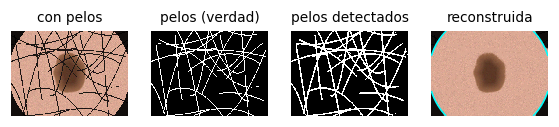

In [26]:
img, info = lesion_de_prueba.generar_lesion(semilla=1, pelos=25)
limpia, valida, pelos = mejoramiento.mejorar(img)
fig, ax = plt.subplots(1, 4)
graficos.mostrar(ax[0], img, "con pelos")
graficos.mostrar(ax[1], info["mascara_pelos"], "pelos (verdad)")
graficos.mostrar(ax[2], pelos, "pelos detectados")
graficos.mostrar(ax[3], limpia, "reconstruida")
ax[3].contour(valida, [0.5], colors="cyan", linewidths=1)

## 1. Análisis exploratorio (metodología 1)

- [x] Histogramas de cada canal RGB y HSV dentro de la lesión y en la piel (con `mascara_ref`): ¿qué canal tiene más contraste? (lo usa M3)
- [x] Fracción de cada imagen cubierta por pelos; ¿cuántas imágenes tienen pelos?
- [x] Valores típicos de cada color en HSV (los usa M4).

El análisis exploratorio consiste en mirar los datos **antes** de programar los pasos siguientes, para tomar decisiones con fundamento y no a ojo. Tiene tres preguntas, y cada una le sirve a un módulo distinto. Todo se calcula con las imágenes de **entrenamiento**.

### 1.1 ¿Qué canal tiene más contraste? (para M3)

**El problema:** para segmentar, M3 necesita una imagen en escala de grises donde la lesión y la piel sean lo más distintas posible. Una imagen RGB tiene tres canales, y se pueden calcular otros, así que hay que elegir uno.

**Los canales que se comparan:**

| Canal | Qué mide |
|---|---|
| R, G, B | Cuánto rojo, verde y azul tiene cada píxel |
| H (matiz) | Qué color es (rojo, naranja, azul...), sin importar lo claro u oscuro |
| S (saturación) | Qué tan "puro" o intenso es el color: 0 = gris, 1 = color vivo |
| V (brillo) | El máximo entre R, G y B |
| L (de Lab) | Luminosidad como la percibe el ojo humano |
| gris | Combinación ponderada de R, G y B |

**Cómo se mide:** en cada imagen se toman 2000 píxeles de lesión (máscara de PH2) y 2000 de piel (fuera de la lesión y lejos de la viñeta), y se calcula el **AUC**: la probabilidad de que un píxel de lesión y uno de piel elegidos al azar queden bien separados por ese canal (1 = separación perfecta, 0,5 = no los distingue). Se usa `max(auc, 1 - auc)` porque no importa la dirección: en B la lesión es más oscura que la piel, pero en S es más alta. Después se promedia sobre las imágenes (`mean`) y se guarda el peor caso (`min`).

In [27]:
rng = np.random.default_rng(0)

def canales(img):
    hsv, lab = color.rgb2hsv(img), color.rgb2lab(img)
    return {"R": img[..., 0], "G": img[..., 1], "B": img[..., 2],
            "H": hsv[..., 0], "S": hsv[..., 1], "V": hsv[..., 2],
            "L (Lab)": lab[..., 0], "gris": color.rgb2gray(img)}

def piel(caso):
    r = mejoramiento._distancia_al_centro(caso.mascara_ref.shape)
    return ~caso.mascara_ref & (r < 0.45 * min(caso.mascara_ref.shape))

filas = []
for caso in entrenamiento:
    p = piel(caso)
    if p.sum() < 100:          # lesiones que casi no dejan piel visible
        continue
    for nombre, x in canales(caso.imagen).items():
        a = rng.choice(x[caso.mascara_ref], 2000)
        b = rng.choice(x[p], 2000)
        auc = roc_auc_score(np.r_[np.ones(2000), np.zeros(2000)], np.r_[a, b])
        filas.append({"canal": nombre, "AUC": max(auc, 1 - auc)})

auc_canal = pd.DataFrame(filas).groupby("canal")["AUC"].agg(["mean", "min"]).sort_values("mean", ascending=False)
auc_canal.round(3)

,mean,min
canal,,
B,0.976,0.776
G,0.965,0.797
gris,0.963,0.803
L (Lab),0.961,0.791
S,0.941,0.581
R,0.902,0.570
V,0.902,0.569
H,0.715,0.505


WindowsPath('C:/Users/Facu/Desktop/1er Cuatri 4to (Bioingenieria)/Procesamiento de Señales e Imagenes Biomedicas/TP Imagenes - Final/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m1_histogramas_canal.pdf')

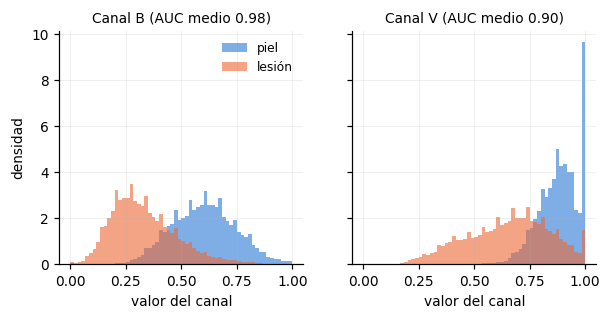

In [28]:
# Histogramas de lesión vs. piel en el mejor canal (B) y en el que proponía el anteproyecto (V)
fig, ax = plt.subplots(1, 2, sharey=True)
for a, canal in zip(ax, ["B", "V"]):
    lesion = np.concatenate([canales(c.imagen)[canal][c.mascara_ref][::50] for c in entrenamiento])
    fondo = np.concatenate([canales(c.imagen)[canal][piel(c)][::50] for c in entrenamiento])
    a.hist(fondo, bins=60, range=(0, 1), density=True, alpha=0.6, color=graficos.COLOR_GRUPO["comun"], label="piel")
    a.hist(lesion, bins=60, range=(0, 1), density=True, alpha=0.6, color=graficos.COLOR_GRUPO["sospechosa"], label="lesión")
    a.set_title(f"Canal {canal} (AUC medio {auc_canal.loc[canal, 'mean']:.2f})")
    a.set_xlabel("valor del canal")
ax[0].set_ylabel("densidad")
ax[0].legend()
graficos.guardar_figura(fig, "m1_histogramas_canal")

**Resultado:** B > G ≈ gris ≈ L > S > R ≈ V > H.

**Por qué gana el azul:** la melanina absorbe mucho más la luz azul que la roja. En el canal B la lesión aparece muy oscura frente a la piel, mientras que en el rojo piel y lesión reflejan parecido. Es lo que muestran los histogramas: en B las dos distribuciones (piel y lesión) están bien separadas, y en V se superponen bastante.

**Por qué V es malo, aunque lo proponía el anteproyecto:** V es el máximo de R, G y B, y en la piel y en los lunares el canal más alto casi siempre es el rojo. Entonces V ≈ R, y hereda su poco contraste.

**Por qué H es el peor:** piel y lunar son casi del mismo matiz (anaranjado o marrón). Lo que cambia es lo oscuro, no el color.

**Qué se decide:** **M3 segmenta sobre B.** M4 (Sobel del borde) y M5 (GLCM) deberían probar B o gris además de V.

### 1.2 ¿Cuántas imágenes tienen pelos? (para la hipótesis 1)

**El problema:** la hipótesis 1 compara métodos para quitar pelos, y sólo tiene sentido evaluarla en imágenes que **tienen** pelos. Hay que saber cuántas son y cuáles.

**Cómo se mide:** en cada imagen se corre el detector de pelos (sección 3) y se calcula qué fracción de la imagen marca como pelo, dentro de la zona válida (fuera de la viñeta), igual que hace `mejorar()`.

In [29]:
# Se cuenta dentro de la zona válida (fuera de la viñeta), como hace mejorar()
fraccion_pelos = pd.Series({c.nombre: mejoramiento.mejorar(c.imagen)[2].mean() for c in entrenamiento})
for limite in (0.01, 0.05, 0.10):
    print(f"imágenes con más del {limite:.0%} marcado como pelo: {(fraccion_pelos > limite).sum()} de {len(fraccion_pelos)}")
print("las 5 con más pelo:", fraccion_pelos.sort_values(ascending=False).head().round(3).to_dict())

imágenes con más del 1% marcado como pelo: 101 de 140
imágenes con más del 5% marcado como pelo: 43 de 140
imágenes con más del 10% marcado como pelo: 30 de 140
las 5 con más pelo: {'IMD003': 0.465, 'IMD408': 0.447, 'IMD423': 0.376, 'IMD403': 0.35, 'IMD418': 0.309}


**Cómo leerlo:** el detector marca *algo* en casi todas las imágenes, pero eso no significa que casi todas tengan pelos. Parte es **falso positivo** (alguna mancha de red que pasa el filtro de forma, sección 3), y parte son pelos aislados que casi no afectan. Las que superan el **10 %** sí tienen pelos visibles (por ejemplo IMD003 o IMD408, con casi la mitad de la imagen cubierta).

**Qué se decide:** para la hipótesis 1, "imagen con pelos" = más del 10 % marcado como pelo, y esas imágenes se revisan a ojo para confirmarlo. Es más honesto que usar cualquier imagen con algo detectado.

### 1.3 ¿Qué valores tiene cada color? (para M4)

**El problema:** el criterio C cuenta cuántos de los 6 colores de la regla aparecen en la lesión. Para eso M4 asigna cada píxel al color más cercano, y necesita **valores de referencia** de cada color (cuánto H, S y V tiene un "marrón oscuro" típico, por ejemplo).

**De dónde se sacan:** PH2 trae, en 27 imágenes, máscaras que marcan regiones de cada color (carpetas `_roi`; el número del final del nombre, `LabelK`, es el código de color). Se calcula la mediana de H, S y V de los píxeles dentro de cada máscara, usando sólo las imágenes de entrenamiento.

In [30]:
import re
from skimage import io

muestras = {c: [] for c in carga_de_datos.COLORES}
imagenes = {c: set() for c in carga_de_datos.COLORES}
nombres_entrenamiento = set(carga_de_datos.nombres("entrenamiento"))
for ruta in carga_de_datos.CARPETA_IMAGENES.glob("*/*_roi/*.bmp"):
    nombre, codigo = ruta.parts[-3], re.search(r"Label(\d)", ruta.name)
    if nombre not in nombres_entrenamiento or codigo is None:
        continue
    color_nombre = carga_de_datos.COLORES[int(codigo.group(1)) - 1]
    m = io.imread(ruta)
    m = (m[..., 0] if m.ndim == 3 else m) > 0
    caso = carga_de_datos.cargar_caso(nombre, tabla)
    muestras[color_nombre].append(mejoramiento.a_hsv(caso.imagen)[m])
    imagenes[color_nombre].add(nombre)

referencias = pd.DataFrame(
    {c: dict(zip(["H", "S", "V"], np.median(np.concatenate(v), axis=0))) if v else {"H": np.nan, "S": np.nan, "V": np.nan}
     for c, v in muestras.items()}).T
referencias["imágenes"] = [len(imagenes[c]) for c in referencias.index]
referencias.round(3)

,H,S,V,imágenes
blanco,0.032,0.309,0.678,2
rojo,NaN,NaN,NaN,0
marron_claro,0.064,0.636,0.694,12
marron_oscuro,0.046,0.463,0.494,13
azul_grisaceo,0.036,0.324,0.443,6
negro,0.037,0.305,0.416,3


**Resultado: estas referencias sirven poco**, por tres razones:

1. **Todos los colores dan un matiz parecido (H ≈ 0,03-0,06, rojizo), incluso el azul grisáceo.** Las máscaras son regiones gruesas que incluyen mucho marrón alrededor, así que no aíslan bien el color que marcan.
2. **El rojo no tiene ninguna muestra** en entrenamiento, y el blanco aparece sólo en 2 imágenes.
3. Algunos valores no tienen sentido: el "negro" tiene V ≈ 0,42, que no es oscuro.

**Qué se decide:** no se pueden usar estas referencias tal cual. M4 necesita otra estrategia: valores de la literatura, trabajar en el espacio Lab (donde las distancias entre colores se parecen más a lo que percibe el ojo) o ajustar las referencias para que la cantidad de colores coincida con el C del dermatólogo en entrenamiento.

### Resumen del exploratorio

| Pregunta | Resultado | Para quién |
|---|---|---|
| Canal con más contraste | **B** (V, el del anteproyecto, está entre los peores) | M3 segmenta sobre B; M4 y M5 prueban B o gris |
| Imágenes con pelos | Las que superan el 10 % marcado como pelo, revisadas a ojo | Hipótesis 1 |
| Referencias de color | Las máscaras `_roi` no sirven tal cual | M4 necesita otra estrategia |

## 2. Viñeta

- [x] Elegir `UMBRAL_VINETA` y mostrar ejemplos. Cuidado: los pelos oscuros que tocan el borde también se conectan con las esquinas.

### Qué es la viñeta

El dermatoscopio se apoya sobre la piel y mira a través de una **lente circular** con luz propia, pero la cámara saca una foto **rectangular**. El círculo de la lente no llega a cubrir las esquinas del rectángulo, y ahí la imagen queda oscura o negra. Además, la luz cae de a poco hacia el borde del círculo, así que la transición no es abrupta: se va oscureciendo.

```
┌──────────────────────────┐
│▓▓▓░                  ░▓▓▓│   ▓ = esquina oscura (viñeta)
│▓░                      ░▓│   ░ = transición
│                          │
│         piel  ●lesión    │   el resto = imagen útil
│▓░                      ░▓│
│▓▓▓░                  ░▓▓▓│
└──────────────────────────┘
```

No es información de la piel: es un **artefacto del equipo**.

### Por qué es un problema

Las esquinas oscuras **se parecen a una lesión**, porque son oscuras igual que el lunar:

- **M3 (segmentación):** Otsu, k-means y los demás métodos separan oscuro de claro, así que las esquinas quedarían marcadas como lesión.
- **M4 (criterios):** el color de la esquina podría contarse como negro o marrón oscuro, y el gradiente entre la esquina y la piel parecería un borde abrupto. Si la lesión segmentada se pega a una esquina, cambian su forma, su asimetría y su contorno.

### Qué hacemos

No se "arregla" la imagen: se construye una máscara llamada **`valida`**, que vale True donde la imagen es útil y False en la viñeta. Los módulos siguientes sólo trabajan donde `valida` es True (por ejemplo, M3 segmenta únicamente dentro de esa zona). El problema es **cómo decidir qué píxeles son viñeta**.

### La idea obvia y por qué falla

La propuesta del anteproyecto era: umbral sobre el brillo (V), quedarse con lo oscuro y descartar las regiones oscuras **conectadas al borde de la imagen**. Falla por tres razones:

1. **El brillo de las esquinas cambia mucho entre imágenes** (celda de abajo): en algunas la viñeta es casi negra y en otras casi no existe. Un umbral bajo no detecta las viñetas suaves; uno alto, que las detecte todas, también toma las partes oscuras de casi todas las lesiones.
2. **En 50 imágenes la lesión toca el borde** (como IMD058): la lesión es oscura y está conectada al borde, así que se descartaría como si fuera viñeta.
3. **Los pelos oscuros que llegan al borde** también quedan conectados con las esquinas y se descartarían igual.

### La idea que usamos: la viñeta es un círculo

Lo que distingue a la viñeta no es su brillo sino su **forma**: siempre es un círculo centrado, porque lo genera la lente. Una lesión, en cambio, está en un solo lugar.

1. Se divide la imagen en **anillos concéntricos** de `ANCHO_ANILLO` = 4 px alrededor del centro (como los anillos de un tronco).
2. En cada anillo se calcula la **mediana** del brillo V.
3. La mediana en función de la distancia al centro es el **perfil radial** (figura de abajo): se mantiene alto en la zona de piel y **cae bruscamente** donde empieza la viñeta.
4. El radio donde la mediana cae por debajo del **60 %** del anillo más brillante (`UMBRAL_VINETA = 0,6`) es el **límite de la viñeta**: todo lo que está más afuera es inválido.

**Por qué la mediana y no el promedio:** si una lesión oscura ocupa una parte de un anillo (por ejemplo un cuarto), el promedio baja, pero la mediana casi no se mueve, porque la mayoría del anillo sigue siendo piel clara. Así la lesión no engaña al método aunque toque el borde. En la viñeta, en cambio, **todo** el anillo es oscuro, y ahí la mediana sí cae.

### El caso que todavía fallaba

En 5 imágenes la lesión es **enorme** (IMD031, IMD065, IMD080, IMD348, IMD411) y ocupa anillos completos: la mediana cae dentro de la lesión y el círculo se cortaba demasiado adentro, perdiendo hasta el **60 %** de la lesión. Por eso se agregó **`RADIO_MINIMO = 0,8`**: la viñeta nunca empieza antes del 80 % de la distancia del centro a la esquina. Funciona porque en PH2 todas las imágenes son del mismo equipo, y la viñeta está siempre aproximadamente en el mismo lugar.

In [31]:
# Brillo de las esquinas vs. zonas oscuras de las lesiones (por qué un umbral fijo no sirve)
v_esquinas, v_lesion = [], []
for caso in entrenamiento:
    v = mejoramiento.a_hsv(caso.imagen)[..., 2]
    e = 15
    v_esquinas.append(np.median(np.r_[v[:e, :e].ravel(), v[:e, -e:].ravel(), v[-e:, :e].ravel(), v[-e:, -e:].ravel()]))
    v_lesion.append(np.percentile(v[caso.mascara_ref], 5))
v_esquinas, v_lesion = np.array(v_esquinas), np.array(v_lesion)
print(f"V de las esquinas: entre {v_esquinas.min():.2f} y {v_esquinas.max():.2f} según la imagen (mediana {np.median(v_esquinas):.2f})")
print(f"V del 5 % más oscuro de cada lesión: entre {v_lesion.min():.2f} y {v_lesion.max():.2f} (mediana {np.median(v_lesion):.2f})")
u = np.percentile(v_esquinas, 95)
print(f"con un umbral que tome el 95 % de las esquinas (V < {u:.2f}), {(v_lesion < u).sum()} de {len(v_lesion)} lesiones tendrían partes por debajo")

V de las esquinas: entre 0.13 y 0.77 según la imagen (mediana 0.23)
V del 5 % más oscuro de cada lesión: entre 0.17 y 0.89 (mediana 0.49)
con un umbral que tome el 95 % de las esquinas (V < 0.69), 124 de 140 lesiones tendrían partes por debajo


WindowsPath('C:/Users/Facu/Desktop/1er Cuatri 4to (Bioingenieria)/Procesamiento de Señales e Imagenes Biomedicas/TP Imagenes - Final/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m1_vineta.pdf')

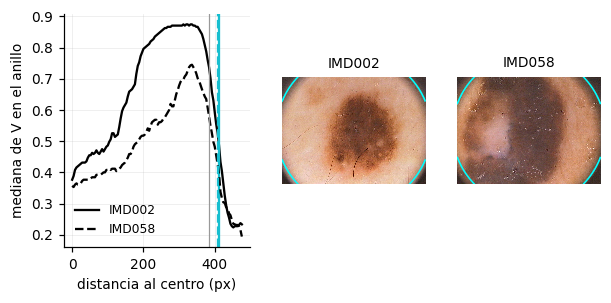

In [32]:
# Perfil radial: mediana de V en anillos, en una imagen normal y en una con lesión que toca el borde
fig, ax = plt.subplots(1, 3, gridspec_kw={"width_ratios": [1.3, 1, 1]})
for nombre, estilo in [("IMD002", "-"), ("IMD058", "--")]:
    caso = carga_de_datos.cargar_caso(nombre, tabla)
    v = mejoramiento.a_hsv(caso.imagen)[..., 2]
    r = mejoramiento._distancia_al_centro(v.shape)
    anillo = (r // mejoramiento.ANCHO_ANILLO).astype(int)
    perfil = [np.median(v[anillo == k]) for k in range(anillo.max() + 1)]
    ax[0].plot(np.arange(len(perfil)) * mejoramiento.ANCHO_ANILLO, perfil, estilo, color="k", label=nombre)
    ax[0].axvline(mejoramiento.radio_vineta(caso.imagen), ls=estilo, color="tab:cyan")
ax[0].axvline(mejoramiento.RADIO_MINIMO * r.max(), color="0.6", lw=0.8)
ax[0].set_xlabel("distancia al centro (px)")
ax[0].set_ylabel("mediana de V en el anillo")
ax[0].legend()
for a, nombre in zip(ax[1:], ["IMD002", "IMD058"]):
    caso = carga_de_datos.cargar_caso(nombre, tabla)
    graficos.mostrar(a, caso.imagen, nombre)
    a.contour(mejoramiento.mascara_vineta(caso.imagen), [0.5], colors="cyan", linewidths=1)
graficos.guardar_figura(fig, "m1_vineta")

In [33]:
# Cuánta lesión se pierde por la viñeta (en las 200: es un control, no se elige nada con esto)
perdida = {}
for nombre in tabla["nombre"]:
    caso = carga_de_datos.cargar_caso(nombre, tabla)
    valida = mejoramiento.mascara_vineta(caso.imagen)
    perdida[nombre] = (caso.mascara_ref & ~valida).sum() / caso.mascara_ref.sum()
perdida = pd.Series(perdida)
print(f"imágenes que pierden más del 2 % de la lesión: {(perdida > 0.02).sum()} de 200 (máximo {perdida.max():.1%})")
perdida.sort_values(ascending=False).head().round(3)

imágenes que pierden más del 2 % de la lesión: 4 de 200 (máximo 5.9%)


IMD411    0.059
IMD061    0.033
IMD064    0.027
IMD240    0.023
IMD409    0.019
dtype: float64

### Conclusiones de la viñeta

Resumen de lo anterior y del resultado en las 200 imágenes:

- `UMBRAL_VINETA = 0,6`: la viñeta empieza donde la mediana del anillo cae por debajo del 60 % del anillo más brillante. Con un umbral fijo sobre V no se puede: el brillo de las esquinas varía mucho entre imágenes y un umbral que las capture a todas captura también partes oscuras de casi todas las lesiones (ver la celda de arriba).
- `RADIO_MINIMO = 0,8` de la semidiagonal: sin este límite, en 5 imágenes con lesiones enormes (IMD031, IMD065, IMD080, IMD348, IMD411) la lesión ocupaba anillos enteros y se confundía con viñeta (se perdía hasta el 60 % de la lesión).
- Resultado: casi ninguna lesión pierde más del 2 % (las que pierden algo son las que se meten en la esquina oscura, donde de todas formas no se ve bien).
- Limitación: se supone que la viñeta está centrada y es circular, lo que vale en PH2 porque todas las imágenes son del mismo equipo.

## 3. Pelos: cierre vs. mediana vs. nada

- [x] Elegir `LARGO_ELEMENTO`, `ORIENTACIONES` y `UMBRAL_PELOS`; justificar.
- [x] Figura para el informe: original, máscara de pelos, resultado con cada método.
- [ ] Hipótesis 1: en las imágenes **con pelos**, Dice de la segmentación con cada método (cuando M3 esté listo: `procesar(caso, hasta="segmentacion", metodo_pelos=...)`).

### El problema

Los pelos son **líneas oscuras y finas** que cruzan la imagen. Si se dejan:

- **M3 (segmentación):** un pelo oscuro que cruza la piel se parece a la lesión, así que la máscara se "escapa" siguiendo el pelo o queda con el borde deformado.
- **M4 (color):** el pelo agrega un color negro o marrón oscuro que no es de la lesión.
- **M5 (textura):** las líneas del pelo cambian el contraste y la entropía que mide la GLCM.

El objetivo es **detectar los pelos y reemplazarlos** por lo que habría debajo, sin tocar el resto de la imagen.

### Los tres métodos que se comparan (hipótesis 1)

| Método | Qué hace |
|---|---|
| **ninguno** | Deja la imagen como está. Es la referencia para ver si quitar pelos ayuda |
| **mediana** | Suaviza **toda** la imagen con un filtro de mediana de `TAMANO_MEDIANA` × `TAMANO_MEDIANA` (9 × 9) |
| **cierre** | **Detecta** los pelos y reconstruye **sólo** esos píxeles |

La hipótesis 1 dice que el cierre debería dar la mejor segmentación.

### Cómo funciona el cierre, paso a paso

**1. La idea del cierre morfológico.** Un **cierre** es una dilatación seguida de una erosión. En una imagen en escala de grises, la **dilatación** reemplaza cada píxel por el **máximo** de su vecindario (las zonas claras "crecen") y la **erosión** por el **mínimo** (las zonas oscuras "crecen"). El efecto combinado: **las estructuras oscuras más chicas que el vecindario desaparecen**, y todo lo demás queda casi igual. Sobre una fila de píxeles que cruza un pelo:

```
original:   ‾‾‾‾‾‾‾‾\_/‾‾‾‾‾‾‾‾      (el pelo es un "pozo" angosto)
cierre:     ‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾      (el pozo se rellena)
```

La lesión también es oscura, pero es **mucho más ancha** que el vecindario, así que el cierre no la rellena.

**2. Segmentos en 12 orientaciones.** Con un elemento estructurante plano, el cierre **conserva una zona oscura sólo si el elemento entra entero dentro de ella**; si no entra, la rellena con el brillo de alrededor. El elemento es un **segmento de `LARGO_ELEMENTO` = 21 px**:

- **Segmento paralelo al pelo:** entra entero dentro del pelo (el pelo es largo), así que el pelo **sobrevive**.
- **Segmento perpendicular al pelo:** no entra (el pelo mide 3-8 px de ancho y el segmento 21), así que el pelo **se rellena**.

Como los pelos van en cualquier dirección, se hacen **`ORIENTACIONES` = 12** cierres (uno cada 15°) y en cada píxel se toma el **máximo**: alcanza con que **una** orientación no entre para que el píxel se rellene. ¿Qué pasa con la lesión? Es ancha en **todas** las direcciones: el segmento entra en las 12 orientaciones, ningún cierre la rellena y el máximo la deja igual.

En resumen, con el máximo de los 12 cierres **se rellena toda zona oscura que mida menos de 21 px en alguna dirección**. Eso incluye pelos, pero también líneas de la red de pigmento y puntos o glóbulos chicos: lo que los separa de los pelos es el filtro de forma del paso 4.

**3. Black-hat: dónde estaba lo oscuro y fino.** Se resta **cierre − original** en cada píxel:

| Píxel | Original | Cierre | Diferencia |
|---|---|---|---|
| piel | 0,80 | 0,80 | 0 |
| pelo sobre la piel | 0,30 | 0,80 (rellenado con la piel de los costados) | **0,50** |
| interior de la lesión | 0,40 | 0,40 (no se rellena: es ancha) | 0 |

La diferencia (llamada ***black-hat***) es alta **sólo donde el cierre rellenó algo**, es decir, en lo oscuro y fino. Los píxeles donde supera **`UMBRAL_PELOS` = 0,10** (un 10 % del rango de brillo) son **candidatos** a pelo. Una línea de la red dentro de la lesión es apenas más oscura que su entorno (por ejemplo 0,32 sobre 0,40) y suele quedar cerca del umbral; las que lo superan las descarta el filtro de forma.

**4. Filtro de forma** (se explica y se muestra más abajo, junto a su figura).

**5. Reconstrucción: inpainting.** Los píxeles marcados como pelo se rellenan con ***inpainting*** (`cv2.inpaint`, método de Telea): se completa cada píxel desde el borde hacia adentro usando los valores de alrededor, como si se "pintara" el hueco continuando lo que hay a los costados. Es la parte de **reconstrucción** que pide la consigna. Lo importante: **sólo cambian los píxeles de pelo**; el resto de la imagen queda idéntico, con la red, el borde de la lesión y los colores intactos.

WindowsPath('C:/Users/Facu/Desktop/1er Cuatri 4to (Bioingenieria)/Procesamiento de Señales e Imagenes Biomedicas/TP Imagenes - Final/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m1_pelos.pdf')

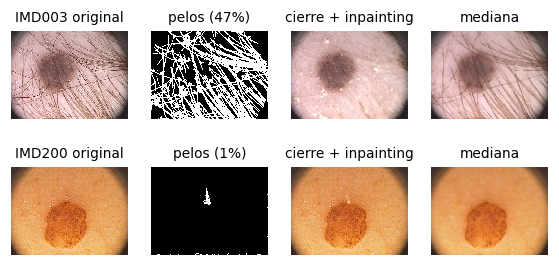

In [34]:
# Figura para el informe: un caso con muchos pelos y uno con red de pigmento marcada (sin pelos)
nombres = ["IMD003", "IMD200"]
fig, ax = plt.subplots(len(nombres), 4, figsize=(16 / 2.54, 7.5 / 2.54))
for fila, nombre in zip(ax, nombres):
    caso = carga_de_datos.cargar_caso(nombre, tabla)
    con_cierre, pelos = mejoramiento.quitar_pelos(caso.imagen, "cierre")
    con_mediana, _ = mejoramiento.quitar_pelos(caso.imagen, "mediana")
    graficos.mostrar(fila[0], caso.imagen, f"{nombre} original")
    graficos.mostrar(fila[1], pelos, f"pelos ({pelos.mean():.0%})")
    graficos.mostrar(fila[2], con_cierre, "cierre + inpainting")
    graficos.mostrar(fila[3], con_mediana, "mediana")
graficos.guardar_figura(fig, "m1_pelos")

**4. Filtro de forma: separar pelos de red de pigmento.** Acá apareció el problema principal: **la red de pigmento también es oscura y fina**, así que el black-hat la marca como pelo, y si se la "reconstruye" se borra justo la textura que M5 tiene que medir. La figura de abajo lo muestra en IMD200, que **no tiene pelos**.

La diferencia está en la **forma**: un **pelo** es **largo, fino y alargado** (se extiende en una dirección), mientras que la red forma **manchas cortas o enmarañadas**. Para cada región candidata se calcula:

- su **largo**: la cantidad de píxeles del **esqueleto** (la línea central de 1 px que queda al "afinar" la región);
- su **ancho medio**: área / largo;
- su **eje mayor**: el largo de la elipse que mejor se ajusta a la región, que mide cuánto se **extiende** en su dirección principal.

Sólo quedan las regiones con **largo ≥ `LARGO_MIN_PELO` = 60 px**, **ancho ≤ `ANCHO_MAX_PELO` = 8 px** y **eje mayor ≥ `EJE_MIN_PELO` = 80 px**. Al final se **dilata 1 px** la máscara, para incluir el borde difuso del pelo, que es un poco más claro que su centro.

**Por qué hace falta el eje mayor:** una mancha de red **enmarañada** tiene un esqueleto largo (60 px o más, sumando todas sus ramitas) y líneas finas, así que pasa las dos primeras condiciones; pero es **compacta**: no se extiende lejos. Un pelo, aunque sea curvo, sí. Con sólo largo y ancho, en IMD200 se marcaba como pelo el **14 % de la lesión**; agregando el eje mayor, el **1 %**, y en las imágenes con muchos pelos (IMD003, IMD408) la detección no cambia.

WindowsPath('C:/Users/Facu/Desktop/1er Cuatri 4to (Bioingenieria)/Procesamiento de Señales e Imagenes Biomedicas/TP Imagenes - Final/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m1_filtro_forma.pdf')

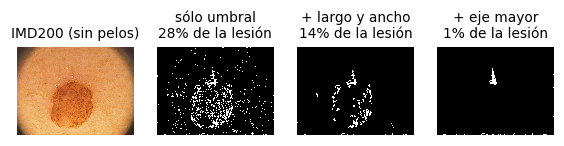

In [35]:
# Por qué hace falta el filtro de forma: sin él (o con un filtro incompleto), la red de pigmento se detecta como pelo
import cv2
from skimage import measure, morphology

caso = carga_de_datos.cargar_caso("IMD200", tabla)
gris = (color.rgb2gray(caso.imagen) * 255).astype(np.uint8)
cierre = np.max([cv2.morphologyEx(gris, cv2.MORPH_CLOSE, se)
                 for se in mejoramiento._elementos_lineales(mejoramiento.LARGO_ELEMENTO, mejoramiento.ORIENTACIONES)], axis=0)
sin_filtro = (cierre.astype(float) - gris) / 255 > mejoramiento.UMBRAL_PELOS

# Filtro sólo con largo y ancho (versión anterior), para mostrar por qué se agregó el eje mayor
etiquetas = measure.label(sin_filtro)
largo_y_ancho = np.zeros_like(sin_filtro)
for region in measure.regionprops(etiquetas):
    largo = morphology.skeletonize(region.image).sum()
    if largo >= mejoramiento.LARGO_MIN_PELO and region.area / max(largo, 1) <= mejoramiento.ANCHO_MAX_PELO:
        largo_y_ancho[etiquetas == region.label] = True

completo = mejoramiento.detectar_pelos(caso.imagen)
lesion = caso.mascara_ref
fig, ax = plt.subplots(1, 4)
graficos.mostrar(ax[0], caso.imagen, "IMD200 (sin pelos)")
for a, m, titulo in [(ax[1], sin_filtro, "sólo umbral"), (ax[2], largo_y_ancho, "+ largo y ancho"), (ax[3], completo, "+ eje mayor")]:
    graficos.mostrar(a, m, f"{titulo}\n{(m & lesion).sum() / lesion.sum():.0%} de la lesión")
graficos.guardar_figura(fig, "m1_filtro_forma")

### Por qué se espera que la mediana sea peor

La mediana no detecta nada: suaviza **toda** la imagen. Un pelo de 3-8 px desaparece con una ventana de 9 × 9, pero también se borran o suavizan:

- la **red de pigmento** y los **puntos**, que son la textura de M5;
- el **borde** de la lesión, que pierde nitidez y afecta al criterio B;
- y los pelos más gruesos que la ventana no se van del todo.

Por eso es una buena comparación: es lo más simple que se podría hacer.

### Limitaciones

- Todavía puede quedar alguna mancha de red marcada como pelo, aunque con el eje mayor es poco (1 % de la lesión en IMD200).
- Los pelos muy gruesos y oscuros se escapan en parte, porque el segmento de 21 px no alcanza a taparlos bien.

Las dos cosas se ajustan con `LARGO_ELEMENTO`, `UMBRAL_PELOS` y los límites del filtro de forma (`LARGO_MIN_PELO`, `ANCHO_MAX_PELO`, `EJE_MIN_PELO`).

### Lo que falta: la hipótesis 1

Cuando M3 esté listo, la celda de abajo (ahora comentada):

1. toma las imágenes "con pelos" (más del 10 % marcado como pelo, ver 1.2);
2. segmenta cada una tres veces, una con cada método;
3. compara el **Dice** con la máscara de PH2.

Si el cierre da el Dice más alto en la mayoría de esas imágenes, la hipótesis 1 se confirma.

In [36]:
# PENDIENTE (cuando M3 esté listo): hipótesis 1
# con_pelos = fraccion_pelos[fraccion_pelos > 0.10].index
# filas = []
# for nombre in con_pelos:
#     caso = carga_de_datos.cargar_caso(nombre, tabla)
#     for metodo in mejoramiento.METODOS_PELOS:
#         res = procesar(caso, hasta="segmentacion", metodo_pelos=metodo)
#         filas.append({"nombre": nombre, "metodo": metodo, "dice": res.dice})
# h1 = pd.DataFrame(filas).pivot(index="nombre", columns="metodo", values="dice")
# h1.describe()